**Universidade Federal do Rio Grande do Norte**

**Disciplina:** PPGEEC2327 - Tópicos Especiais em Processamento Inteligente da Informação

**Discente:** José Augusto Agripino de Oliveira

# Classificação de fraturas em afloramento com AlexNet

Laboratório: [Identifying Rock Crack by Convolutional Neural Network](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.Book.CNN/Chapter.CNNCrack/lab.html) (S. Feng).

O ponto de partida é uma foto de afloramento em tons de cinza, com $457\times977$ pixels, e a pergunta é: cada pixel está sobre uma fratura ou não? Um pixel sozinho diz pouco, então a rede olha para a vizinhança dele, uma janela de $17\times17$ px centrada no pixel, e decide entre **fratura** ($y=1$) e **não fratura** ($y=0$). Repetindo isso para todos os pixels, obtém-se um mapa de fraturas da imagem inteira.

Para treinar, basta marcar à mão algumas centenas de pontos de cada classe. A rede aprende com as janelas desses pontos e depois generaliza para o resto da imagem.

**AlexNet e CNN do lab.** A atividade pede para completar o laboratório classificando as fraturas com a **AlexNet**. O código que acompanha o laboratório, porém, usa uma CNN pequena, e as questões do lab se referem a ela ("modifique a estrutura da CNN", "use este código"). Por isso, todos os experimentos são feitos com as duas redes, lado a lado:

* **AlexNet**, o classificador pedido na atividade: uma rede grande, já treinada com 1,2 milhão de fotos do ImageNet e ajustada às janelas da imagem (*transfer learning*);
* **CNN do lab**, a referência de comparação: uma rede pequena, com duas camadas convolucionais e 2 570 parâmetros, reescrita em PyTorch com a mesma arquitetura e os mesmos hiperparâmetros da versão original em MATLAB.

**Roteiro.** As seções 2 e 3 descrevem as duas redes. A seção 4 refaz o lab com os pontos de treino que ele fornece. Esses pontos têm um problema sério, descrito na seção 1, e por isso a seção 5 refaz a marcação dos pontos "não fratura". A seção 6 responde às quatro questões do lab com as duas redes; na questão 2, que trata da estrutura da CNN do lab, a AlexNet entra como a mudança de estrutura mais radical. A seção 7 reúne os resultados, e a discussão final os interpreta.

**Como executar.** Use o ambiente `.venv` do projeto (PyTorch para CPU). Os pontos marcados à mão estão salvos em `picks_nao_fratura.csv` e `picks_grandes_pequenas.csv` e são reaproveitados automaticamente. As figuras clicáveis das seções 5 e 6.3 só abrem para refazer a marcação; elas precisam do pacote `ipympl` e, no VS Code, da permissão para baixar os scripts de widgets (configuração `jupyter.widgetScriptSources`). Na primeira execução, os pesos da AlexNet (233 MB) são baixados. A execução completa leva cerca de 50 min numa CPU de 8 núcleos, quase todo esse tempo nos treinos da AlexNet.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import scipy.io as sio
from scipy import ndimage as ndi
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import alexnet, AlexNet_Weights
from IPython.display import display
import ipywidgets as widgets

plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
SEMENTE = 0          # inicialização, ordem dos minilotes e divisão treino/validação
DADOS = Path('CNN_lab/CNN_lab/data')
COR = {'CNN do lab': '#2a78d6', 'AlexNet': '#eb6834'}
FRATURA = ListedColormap(['#1a1a19', '#f0c419'])                                  # não fratura, fratura
CONCORDA = ListedColormap(['#1a1a19', COR['CNN do lab'], COR['AlexNet'], '#f0efec'])
RES = {}             # resumo de cada experimento, reunido na seção 7

## 1. A imagem e os pontos de treino do lab

O lab fornece a imagem, com valores entre $-1$ (escuro) e $1$ (claro), e 400 pontos de treino já marcados à mão: 200 sobre fraturas e 200 fora delas. Abaixo, os pontos aparecem sobre a foto, com um zoom no canto superior esquerdo.

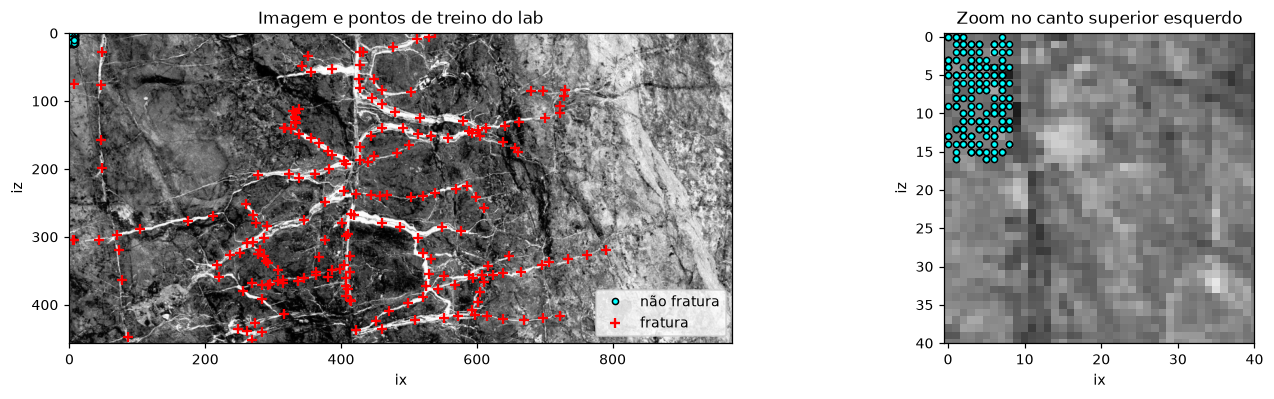

200 pontos de fratura: ix de 5 a 791, iz de 0 a 452
200 pontos não fratura: ix de 0 a 8, iz de 0 a 16, 105 posições distintas


In [2]:
img = sio.loadmat(DADOS / 'image_input.mat')['image_input'].astype(np.float32)
nz, nx = img.shape
tr = sio.loadmat(DADOS / 'train_new.mat', squeeze_me=True, struct_as_record=False)['train']
lab = pd.DataFrame({'ix': tr.trainx.astype(int) - 1, 'iz': tr.trainz.astype(int) - 1,   # o MATLAB indexa a partir de 1
                    'classe': tr.label[0].astype(int)})                                   # 1ª linha do one-hot: 1 = fratura
ESTILO = {0: dict(marker='o', mfc='cyan', mec='k', ms=4, label='não fratura'),
          1: dict(marker='+', color='r', mew=1.5, ms=6, label='fratura')}


def mostra(a, conj=None, titulo='', estilo=ESTILO):
    a.imshow(img, cmap='gray', vmin=-1, vmax=1)
    if conj is not None:
        for c, e in estilo.items():
            s = conj[conj.classe == c]
            a.plot(s.ix, s.iz, ls='none', **e)
    a.set_title(titulo); a.set_xlabel('ix'); a.set_ylabel('iz')


fig, ax = plt.subplots(1, 2, figsize=(13, 3.7), gridspec_kw={'width_ratios': [nx / nz, 1]})
mostra(ax[0], lab, 'Imagem e pontos de treino do lab'); ax[0].legend(loc='lower right')
mostra(ax[1], lab, 'Zoom no canto superior esquerdo'); ax[1].set_xlim(-0.5, 40); ax[1].set_ylim(40, -0.5)
plt.tight_layout(); plt.show()

fr, nf = lab[lab.classe == 1], lab[lab.classe == 0]
print(f'{len(fr)} pontos de fratura: ix de {fr.ix.min()} a {fr.ix.max()}, iz de {fr.iz.min()} a {fr.iz.max()}')
print(f'{len(nf)} pontos não fratura: ix de {nf.ix.min()} a {nf.ix.max()}, iz de {nf.iz.min()} a {nf.iz.max()}, '
      f'{len(nf.drop_duplicates(["ix", "iz"]))} posições distintas')

**Um problema nos pontos do lab.** Os 200 pontos de fratura estão bem espalhados pelas fraturas da metade esquerda da imagem. Já os 200 pontos "não fratura" estão todos amontoados no canto superior esquerdo, numa área de apenas $9\times17$ px, e só 105 deles caem em pixels diferentes. Como cada janela tem $17\times17$ px, as 200 janelas "não fratura" são praticamente recortes do mesmo pedaço de rocha.

Com esses exemplos, a rede não aprende o que é rocha sem fratura em geral. Ela aprende que "não fratura" é a textura daquele canto, e qualquer coisa diferente dele tende a virar fratura. A faixa clara da direita (ix ≳ 700), por exemplo, não tem nenhum ponto marcado. A seção 4 mostra a consequência.

## 2. A CNN do lab (referência)

É a rede do código do laboratório. Nos experimentos, ela serve de referência para a AlexNet.

**Da janela à classe.** A rede classifica um pixel por vez: recebe a janela de $17\times17$ px centrada nele e devolve duas notas, uma para "não fratura" e outra para "fratura". A maior nota decide a classe. Nas bordas, a imagem é estendida repetindo os pixels da margem, para que todo pixel tenha uma janela completa.

**Arquitetura.** A janela é primeiro ampliada para $32\times32$ px por interpolação, um tamanho escolhido para que as dimensões fiquem pares antes de cada redução pela metade:

```
janela 17×17 → ampliada para 32×32
→ convolução com 6 filtros 5×5   → 6 mapas de 28×28  → média 2×2 → 6 mapas de 14×14
→ convolução com 12 filtros 5×5  → 12 mapas de 10×10 → média 2×2 → 12 mapas de 5×5 = 300 valores
→ camada totalmente conectada    → 2 notas
```

Cada filtro de convolução procura um padrão local, como uma linha clara ou uma borda, e produz um mapa que indica onde esse padrão aparece na janela. A média $2\times2$ resume cada bloco de 4 pixels num só, reduzindo o mapa pela metade. No fim, a camada totalmente conectada combina os 300 valores numa nota para cada classe. Todas as camadas usam a função sigmoide (a figura do lab menciona ReLU, mas o código do lab usa sigmoide), e a rede inteira tem só 2 570 parâmetros.

**Treino.** A rede aprende reduzindo o erro quadrático entre suas notas e a resposta certa: 1 para a classe correta e 0 para a outra. Os pesos são ajustados por gradiente descendente com passo 1, em lotes de 20 janelas, durante 10 épocas. Uma época é uma passada completa pelos pontos de treino, e a ordem dos pontos é sorteada a cada época.

**Validação.** O lab treina com todos os 400 pontos. Aqui, 20 % dos pontos de cada classe ficam fora do treino e servem para medir o acerto em pontos que a rede nunca viu. Essa medida é essencial na questão 3.

**Mapa.** Depois do treino, a janela de cada um dos 446 489 pixels passa pela rede, e o resultado é o mapa de fraturas.

O argumento `moderna` da rede só é usado na questão 2.

In [3]:
WD, NOVO, PAD = 8, 32, 16                  # janela de 17 x 17 px, ampliada para 32 x 32 dentro da rede
img_pad = np.pad(img, PAD, mode='edge')     # repete os pixels da margem, para que a borda também tenha janela


def janelas(iz, ix, wd=WD):
    # janela (2wd+1) x (2wd+1) centrada em cada pixel (iz, ix)
    o = np.arange(-wd, wd + 1) + PAD
    return torch.from_numpy(img_pad[iz[:, None, None] + o[None, :, None], ix[:, None, None] + o[None, None, :]])


class CNNLab(nn.Module):
    # conv 5x5 -> média 2x2 -> conv 5x5 -> média 2x2 -> totalmente conectada
    def __init__(self, n_saidas=2, mapas=(6, 12), k=5, moderna=False):
        super().__init__()
        self.moderna = moderna                                    # ReLU + max-pooling + entropia cruzada (questão 2)
        self.c1, self.c2 = nn.Conv2d(1, mapas[0], k), nn.Conv2d(mapas[0], mapas[1], k)
        lado = ((NOVO - k + 1) // 2 - k + 1) // 2                 # 32 -> 28 -> 14 -> 10 -> 5
        self.fc = nn.Linear(mapas[1] * lado**2, n_saidas)
        for c in (self.c1, self.c2):                              # mesma inicialização do código do lab
            r = np.sqrt(6 / ((c.in_channels + c.out_channels) * k * k))
            nn.init.uniform_(c.weight, -r, r); nn.init.zeros_(c.bias)
        r = np.sqrt(6 / (n_saidas + self.fc.in_features))
        nn.init.uniform_(self.fc.weight, -r, r); nn.init.zeros_(self.fc.bias)

    def forward(self, x):
        x = F.interpolate(x[:, None], size=NOVO, mode='bilinear', align_corners=True)   # amplia a janela para 32 x 32
        ativ, pool = (F.relu, F.max_pool2d) if self.moderna else (torch.sigmoid, F.avg_pool2d)
        x = self.fc(pool(ativ(self.c2(pool(ativ(self.c1(x)), 2))), 2).flatten(1))
        return x if self.moderna else torch.sigmoid(x)            # saída j: nota da classe j


def custo(net, s, y):
    if net.moderna:
        return F.cross_entropy(s, y)
    return 0.5 * ((s - F.one_hot(y, s.shape[1]).float()) ** 2).sum() / len(y)            # erro quadrático, como no lab


def dividir(conj, frac_val=0.2, seed=SEMENTE):
    # separa 20 % dos pontos de cada classe para validação
    r = np.random.default_rng(seed)
    val = np.zeros(len(conj), bool)
    for c in np.unique(conj.classe):
        i = np.flatnonzero(conj.classe.values == c)
        val[r.choice(i, round(frac_val * len(i)), replace=False)] = True
    return conj.reset_index(drop=True).assign(val=val)


def historico(net, s, y, sv, yv):
    return {'custo treino': custo(net, s, y).item(), 'custo validação': custo(net, sv, yv).item(),
            'acerto treino': (s.argmax(1) == y).float().mean().item(), 'acerto validação': (sv.argmax(1) == yv).float().mean().item()}


def treinar_cnn_lab(conj, epocas=10, alfa=1.0, lote=20, wd=WD, seed=SEMENTE, **arq):
    # SGD sem momento: a cada época, sorteia a ordem dos pontos e percorre os minilotes
    torch.manual_seed(seed)
    net = CNNLab(n_saidas=conj.classe.max() + 1, **arq)
    net.wd = wd
    X, y = janelas(conj.iz.values, conj.ix.values, wd), torch.tensor(conj.classe.values)
    v = torch.tensor(conj.val.values)
    Xt, yt, Xv, yv = X[~v], y[~v], X[v], y[v]
    opt = torch.optim.SGD(net.parameters(), lr=alfa)
    hist, t0 = [], time.perf_counter()
    for _ in range(epocas):
        ordem = torch.randperm(len(yt))
        for b in range(len(yt) // lote):
            i = ordem[b * lote:(b + 1) * lote]
            opt.zero_grad(); custo(net, net(Xt[i]), yt[i]).backward(); opt.step()
        with torch.no_grad():
            hist.append(historico(net, net(Xt), yt, net(Xv), yv))
    net.tempo = time.perf_counter() - t0
    net.hist = pd.DataFrame(hist, index=pd.RangeIndex(1, epocas + 1, name='época'))
    return net


def mapa_cnn_lab(net, colunas=40):
    # classifica a janela de todos os pixels, em blocos de colunas
    S = np.zeros((net.fc.out_features, nz, nx), np.float32)
    t0 = time.perf_counter()
    with torch.no_grad():
        for j in range(0, nx, colunas):
            Z, X = np.meshgrid(np.arange(nz), np.arange(j, min(j + colunas, nx)), indexing='ij')
            S[:, :, j:j + colunas] = net(janelas(Z.ravel(), X.ravel(), net.wd)).T.reshape(-1, *Z.shape).numpy()
    net.tempo_mapa = time.perf_counter() - t0
    return S.argmax(0)

## 3. AlexNet (o classificador da atividade)

A AlexNet venceu a competição ImageNet de 2012, aprendendo a reconhecer 1 000 classes de objetos em 1,2 milhão de fotos. É uma rede muito maior que a CNN do lab:

```
imagem 3×224×224
→ 5 camadas convolucionais (filtros de 11×11 a 3×3, com ReLU e max-pooling) → 256 mapas de 6×6 = 9 216 valores
→ fc6: 9 216 → 4 096
→ fc7: 4 096 → 4 096
→ fc8: 4 096 → 1 000   (as classes do ImageNet)
→ fc9: 1 000 → 2       (camada nova: não fratura ou fratura)
```

**Transfer learning.** Uma rede desse tamanho, treinada do zero com algumas centenas de pontos, apenas decoraria os exemplos. A solução é aproveitar o que ela já aprendeu: seus filtros reconhecem bordas, linhas e texturas, que também servem para identificar fraturas. Todas as camadas originais são mantidas, inclusive a fc8 com as 1 000 classes do ImageNet, e uma camada nova, a fc9, combina essas 1 000 saídas em duas classes. A rede fica com cerca de 61 milhões de parâmetros. Na questão 4, com três classes, a fc9 ganha uma terceira saída (1 000 → 3).

**Entrada.** A AlexNet espera imagens coloridas de $224\times224$ px. A mesma janela de $17\times17$ px da CNN do lab é ampliada por interpolação para $224\times224$, copiada nos três canais de cor (a foto é em tons de cinza) e normalizada com a média e o desvio das fotos do ImageNet. A ampliação não acrescenta informação: a rede continua vendo os mesmos $17\times17$ pixels, só que na escala que conhece.

**Treino.** Os hiperparâmetros seguem o exemplo de *transfer learning* com AlexNet da documentação do MATLAB: gradiente descendente com momento 0,9, lotes de 10 janelas, 6 épocas, regularização L2 de $10^{-4}$ e entropia cruzada como custo. As camadas pré-treinadas mudam devagar (passo $10^{-4}$), para não perder o que já sabem, e a fc9, que começa com pesos aleatórios, aprende 20 vezes mais rápido (passo $2\times10^{-3}$).

**Mapa.** Em CPU, a AlexNet processa cerca de 230 janelas por segundo, e classificar os 446 489 pixels levaria uns 33 min. Por isso ela classifica só um pixel a cada 4, nas duas direções (28 175 janelas, cerca de 2 min), e a probabilidade de cada classe é interpolada para os pixels intermediários. Como a janela tem 17 px, pixels vizinhos têm janelas quase iguais, e o mapa perde pouco detalhe.

In [4]:
PESOS = AlexNet_Weights.IMAGENET1K_V1
MEDIA = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)       # normalização do ImageNet
DESVIO = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def entrada_alexnet(x):
    # janela em [-1, 1] -> imagem 3 x 224 x 224 em tons de cinza, normalizada como no ImageNet
    x = F.interpolate(x[:, None], size=224, mode='bilinear', align_corners=True)
    return ((x + 1) / 2 - MEDIA) / DESVIO


def treinar_alexnet(conj, epocas=6, lote=10, seed=SEMENTE):
    torch.manual_seed(seed)
    net = alexnet(weights=PESOS)                                        # fc8 pré-treinada: 4096 -> 1000 classes do ImageNet
    net.classifier.append(nn.Linear(1000, conj.classe.max() + 1))       # fc9 nova: 1000 -> 2 (não fratura, fratura)
    net.moderna = True                                                  # custo: entropia cruzada
    nova = list(net.classifier[7].parameters())
    base = [p for n, p in net.named_parameters() if not n.startswith('classifier.7')]
    opt = torch.optim.SGD([{'params': base, 'lr': 1e-4}, {'params': nova, 'lr': 20 * 1e-4}], momentum=0.9, weight_decay=1e-4)
    X, y = janelas(conj.iz.values, conj.ix.values), torch.tensor(conj.classe.values)
    v = torch.tensor(conj.val.values)
    Xt, yt, Xv, yv = X[~v], y[~v], X[v], y[v]
    hist, t0 = [], time.perf_counter()
    for _ in range(epocas):
        net.train()                                                     # liga o dropout das camadas fc6 e fc7
        ordem = torch.randperm(len(yt))
        for b in range(0, len(yt), lote):
            i = ordem[b:b + lote]
            opt.zero_grad(); F.cross_entropy(net(entrada_alexnet(Xt[i])), yt[i]).backward(); opt.step()
        net.eval()
        with torch.inference_mode():
            hist.append(historico(net, net(entrada_alexnet(Xt)), yt, net(entrada_alexnet(Xv)), yv))
    net.tempo = time.perf_counter() - t0
    net.hist = pd.DataFrame(hist, index=pd.RangeIndex(1, epocas + 1, name='época'))
    return net


def mapa_alexnet(net, passo=4, lote=256):
    # classifica uma grade com passo de 4 px e interpola a probabilidade de cada classe para todos os pixels
    gz, gx = np.arange(0, nz, passo), np.arange(0, nx, passo)
    assert gz[-1] == nz - 1 and gx[-1] == nx - 1                        # a grade cobre a imagem até a borda
    Z, X = (a.ravel() for a in np.meshgrid(gz, gx, indexing='ij'))
    P, t0 = [], time.perf_counter()
    with torch.inference_mode():
        for b in range(0, len(Z), lote):
            P.append(F.softmax(net(entrada_alexnet(janelas(Z[b:b + lote], X[b:b + lote]))), 1))
    P = torch.cat(P).T.reshape(1, -1, len(gz), len(gx))
    net.tempo_mapa = time.perf_counter() - t0
    return F.interpolate(P, size=(nz, nx), mode='bilinear', align_corners=True)[0].argmax(0).numpy()

## 4. Resultado com os pontos do lab

As duas redes são treinadas com os pontos fornecidos pelo lab. Não há um mapa de fraturas "verdadeiro" para comparar, então, além de olhar os mapas, a tabela traz três medidas simples:

* **fratura em ix ≥ 800:** quanto da faixa clara da direita foi classificado como fratura. Nenhum ponto de treino cai nessa faixa, então ela mostra como a rede se comporta numa rocha que nunca viu;
* **regiões de fratura:** quantas manchas de fratura separadas o mapa tem;
* **fratura em regiões < 50 px:** que parte da área de fratura está em manchas pequenas e isoladas. Fraturas reais são longas e contínuas, então essas manchas costumam ser ruído.

O painel de concordância sobrepõe os dois mapas: branco onde as duas redes marcam fratura, azul onde só a CNN do lab marca e laranja onde só a AlexNet marca.

In [5]:
CLARA = slice(800, None)            # colunas da faixa clara da direita


def fragmentos(c, min_px=50):
    rot, n = ndi.label(c > 0, structure=np.ones((3, 3)))
    tam = np.bincount(rot.ravel())[1:]
    return n, 100 * tam[tam < min_px].sum() / max(tam.sum(), 1)


def resumo(net, c):
    h, (n, frag) = net.hist.iloc[-1], fragmentos(c)
    return {'acerto treino (%)': 100 * h['acerto treino'], 'acerto validação (%)': 100 * h['acerto validação'],
            'pixels fratura (%)': 100 * (c > 0).mean(), 'fratura em ix ≥ 800 (%)': 100 * (c[:, CLARA] > 0).mean(),
            'regiões de fratura': n, 'fratura em regiões < 50 px (%)': frag,
            'tempo de treino (s)': net.tempo, 'tempo do mapa (s)': net.tempo_mapa,
            'parâmetros': sum(p.numel() for p in net.parameters())}


def tabela(linhas, transpor=False):
    inteiro = ('regiões de fratura', 'parâmetros')
    df = pd.DataFrame(linhas).apply(lambda col: pd.Series(
        [f'{v:,.0f}'.replace(',', ' ') if k in inteiro else f'{v:.1f}' for k, v in col.items()], index=col.index))
    display(df.T if transpor else df)


def desenha(a, c, titulo, cmap=FRATURA):
    a.imshow(c, cmap=cmap, vmin=0, vmax=cmap.N - 1, interpolation='nearest')
    a.set_title(titulo); a.set_xlabel('ix'); a.set_ylabel('iz')


def compara(c_lab, c_alex, conj, titulo):
    fig, ax = plt.subplots(2, 2, figsize=(13, 6.6))
    mostra(ax[0, 0], conj, f'Imagem e pontos de treino ({titulo})'); ax[0, 0].legend(loc='lower right', fontsize=7)
    desenha(ax[0, 1], c_lab, 'CNN do lab (amarelo = fratura)')
    desenha(ax[1, 0], c_alex, 'AlexNet (amarelo = fratura)')
    desenha(ax[1, 1], c_lab + 2 * c_alex, 'Concordância (branco: ambas; azul: só CNN do lab; laranja: só AlexNet)', CONCORDA)
    plt.tight_layout(h_pad=2); plt.show()

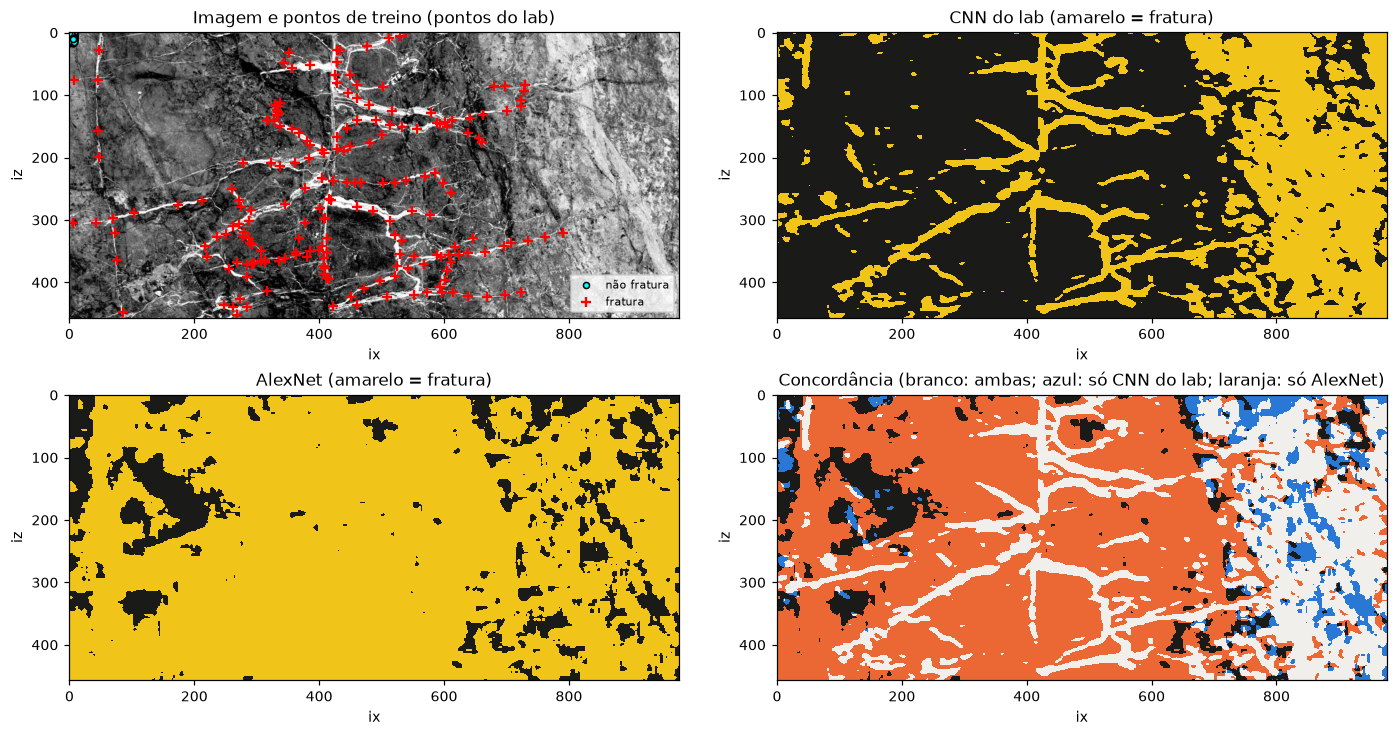

,CNN do lab,AlexNet
acerto treino (%),82.5,100.0
acerto validação (%),83.7,100.0
pixels fratura (%),33.3,85.5
fratura em ix ≥ 800 (%),83.2,77.1
regiões de fratura,151,38
fratura em regiões < 50 px (%),0.9,0.1
tempo de treino (s),0.4,105.0
tempo do mapa (s),11.2,190.2
parâmetros,2 570,61 102 842


In [6]:
conj_lab = dividir(lab)
cnn_lab = treinar_cnn_lab(conj_lab); c_cnn_lab = mapa_cnn_lab(cnn_lab)
alex_lab = treinar_alexnet(conj_lab); c_alex_lab = mapa_alexnet(alex_lab)
compara(c_cnn_lab, c_alex_lab, conj_lab, 'pontos do lab')
RES['4. lab: CNN do lab'], RES['4. lab: AlexNet'] = resumo(cnn_lab, c_cnn_lab), resumo(alex_lab, c_alex_lab)
tabela({'CNN do lab': RES['4. lab: CNN do lab'], 'AlexNet': RES['4. lab: AlexNet']})

**O que os mapas mostram.**

* **CNN do lab:** as fraturas da metade esquerda aparecem bem desenhadas, reproduzindo o resultado do lab. Mas 33 % dos pixels são classificados como fratura, inclusive 83 % da faixa clara da direita. A rede, pequena e com sigmoides, aprendeu uma regra simples, próxima de "pixel claro no centro da janela = fratura". Na metade esquerda, onde as fraturas são as feições mais claras, a regra funciona; na faixa da direita, onde a rocha toda é clara, ela falha.
* **AlexNet:** marca 85 % da imagem como fratura, inclusive quase toda a rocha escura entre as fraturas; só algumas manchas escuras ficam como "não fratura". Com muito mais capacidade, a rede aprendeu exatamente o que os pontos ensinam: "não fratura" é a textura do canto superior esquerdo, e todo o resto é fratura.
* **Acerto:** a CNN do lab acerta 84 % dos pontos de validação e a AlexNet, 100 %. Esse acerto engana: os pontos de validação têm o mesmo viés dos de treino (todos os "não fratura" estão no canto), então ele só mede se a rede separa as fraturas daquele canto, e não se o mapa está certo.

A rede mais poderosa produz o pior mapa. O problema não está na rede, e sim nos dados de treino: uma rede só aprende o que os exemplos mostram. É isso que motiva o novo picking da seção 5.

## 5. Novo picking dos pontos "não fratura"

Os 200 pontos de fratura do lab estão bem distribuídos e foram mantidos. Os pontos "não fratura" foram marcados de novo, à mão, numa figura interativa, espalhados pela rocha escura entre as fraturas, nas partes esquerda e central da imagem (ix < 580). A faixa clara da direita não recebeu pontos. Como só os pontos "não fratura" mudaram, a comparação com a seção 4 mostra o efeito desses exemplos.

**Para refazer a marcação.** Os pontos estão salvos em `picks_nao_fratura.csv` e são reaproveitados. Para marcar de novo, ponha `REFAZER_NAO_FRATURA = True` e execute a célula. Na figura, o clique esquerdo marca um ponto (círculo ciano), e o clique direito ou o botão **Desfazer último ponto** remove o último. Para dar zoom, use a lupa da barra da figura e desligue-a antes de voltar a clicar. As cruzes vermelhas são os pontos de fratura do lab, só como referência. Ao completar os 200 pontos, eles são salvos (o arquivo anterior vira `picks_nao_fratura_anterior.csv`); depois, execute a próxima célula.

In [8]:
REFAZER_NAO_FRATURA = False
N_NAO_FRATURA = 200
ARQ_NAO_FRATURA = Path('picks_nao_fratura.csv')


class Picking:
    # Figura clicável para marcar pontos. etapas: [(classe, n, nome, estilo, cor do título), ...]

    def __init__(self, ax, etapas, arquivo):
        self.ax, self.etapas, self.arquivo = ax, etapas, arquivo
        self.pontos, self.marcas, self.salvo = [], [], False
        self.atualizar()

    def faltam(self, etapa):
        return etapa[1] - sum(p[2] == etapa[0] for p in self.pontos)

    def etapa(self):
        return next((e for e in self.etapas if self.faltam(e) > 0), None)     # primeira etapa incompleta

    def clique(self, ev):
        if ev.inaxes is not self.ax or getattr(getattr(ev.canvas, 'toolbar', None), 'mode', ''):
            return                                            # fora da imagem ou zoom/pan ativo
        if ev.button == 3:
            self.desfazer()
        elif ev.button == 1 and (e := self.etapa()):
            ix = int(np.clip(round(ev.xdata), 0, nx - 1))
            iz = int(np.clip(round(ev.ydata), 0, nz - 1))
            if any((ix, iz) == p[:2] for p in self.pontos):
                return                                        # pixel já marcado
            self.pontos.append((ix, iz, e[0]))
            self.marcas.append(self.ax.plot(ix, iz, ls='none', **e[3])[0])
            self.atualizar()

    def desfazer(self, *_):
        if self.pontos:
            self.pontos.pop()
            self.marcas.pop().remove()
            self.atualizar()

    def atualizar(self):
        e = self.etapa()
        if e is None:
            np.savetxt(self.arquivo, np.array(self.pontos), fmt='%d', delimiter=',', header='ix,iz,classe', comments='')
            self.salvo = True
            txt, cor = f'Concluído: {len(self.pontos)} pontos salvos em {self.arquivo}. Execute a próxima célula.', 'green'
        else:
            if self.salvo:                                    # desfez depois de salvar: o arquivo deixa de valer
                self.arquivo.unlink(missing_ok=True); self.salvo = False
            txt, cor = f'Clique em {e[2]}: faltam {self.faltam(e)} de {e[1]}', e[4]
        self.ax.set_title(txt, color=cor)
        self.ax.figure.canvas.draw_idle()


def picking(etapas, arquivo, refazer, referencia=None):
    # abre a figura clicável, ou reaproveita os pontos já salvos em arquivo
    if arquivo.exists() and not refazer:
        print(f'Usando os pontos já salvos em {arquivo} (ponha o REFAZER correspondente em True para refazer).')
        return None
    try:                                                         # figura clicável dentro do notebook (ipympl)
        get_ipython().run_line_magic('matplotlib', 'widget')
        no_notebook = True
    except (ImportError, RuntimeError):                          # kernel sem ipympl: abre uma janela separada
        get_ipython().run_line_magic('matplotlib', 'tk')
        no_notebook = False
        print('ipympl não encontrado neste kernel: o picking abre numa janela separada (pip install ipympl e reinicie o kernel para clicar no notebook).')
    if arquivo.exists():
        arquivo.replace(arquivo.with_name(arquivo.stem + '_anterior.csv'))
    with plt.ioff():
        fig, ax = plt.subplots(figsize=(11, 5.6))
    mostra(ax, referencia, estilo={1: dict(marker='+', color='r', mew=1, ms=5)})
    fig.tight_layout()
    p = Picking(ax, etapas, arquivo)
    fig.canvas.mpl_connect('button_press_event', p.clique)
    if no_notebook:
        fig.canvas.header_visible = False
        botao = widgets.Button(description='Desfazer último ponto', icon='undo')
        botao.on_click(p.desfazer)
        display(widgets.VBox([botao, fig.canvas]))
    else:
        plt.show(block=False)
    return p


def carregar(arquivo):
    if not arquivo.exists():
        raise RuntimeError(f'Termine o picking na figura acima e execute esta célula de novo ({arquivo} ainda não existe).')
    plt.close('all')                                             # fecha a figura do picking
    get_ipython().run_line_magic('matplotlib', 'inline')       # volta às figuras estáticas
    return pd.read_csv(arquivo)


pick_nf = picking([(0, N_NAO_FRATURA, 'pontos NÃO FRATURA', ESTILO[0], 'darkcyan')], ARQ_NAO_FRATURA, REFAZER_NAO_FRATURA,
                  referencia=lab[lab.classe == 1])

200 pontos de fratura (lab) e 200 pontos não fratura (novo picking), 0 deles em ix ≥ 800


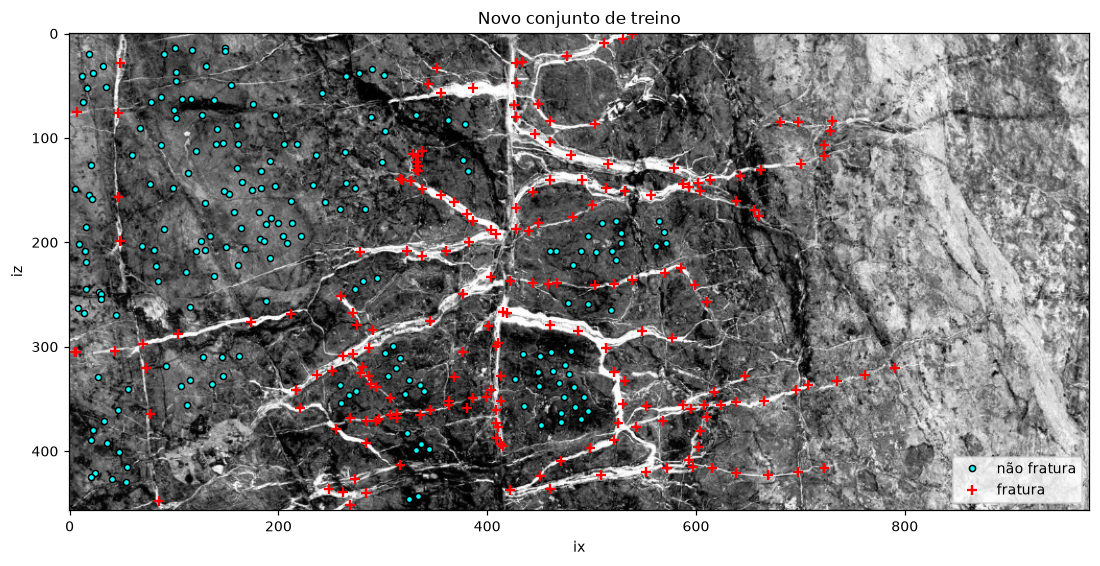

In [8]:
nao = carregar(ARQ_NAO_FRATURA)
novo = dividir(pd.concat([lab[lab.classe == 1], nao], ignore_index=True))
print(f'{(novo.classe == 1).sum()} pontos de fratura (lab) e {(novo.classe == 0).sum()} pontos não fratura (novo picking), '
      f'{(nao.ix >= 800).sum()} deles em ix ≥ 800')
fig, ax = plt.subplots(figsize=(11, 5.2))
mostra(ax, novo, 'Novo conjunto de treino'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

### 5.1 Resultado com o novo conjunto de treino

Mesmas redes, mesmos hiperparâmetros e mesma divisão entre treino e validação da seção 4. Só os pontos "não fratura" mudaram, então as diferenças entre os mapas desta seção e os da seção 4 vêm apenas dos dados de treino.

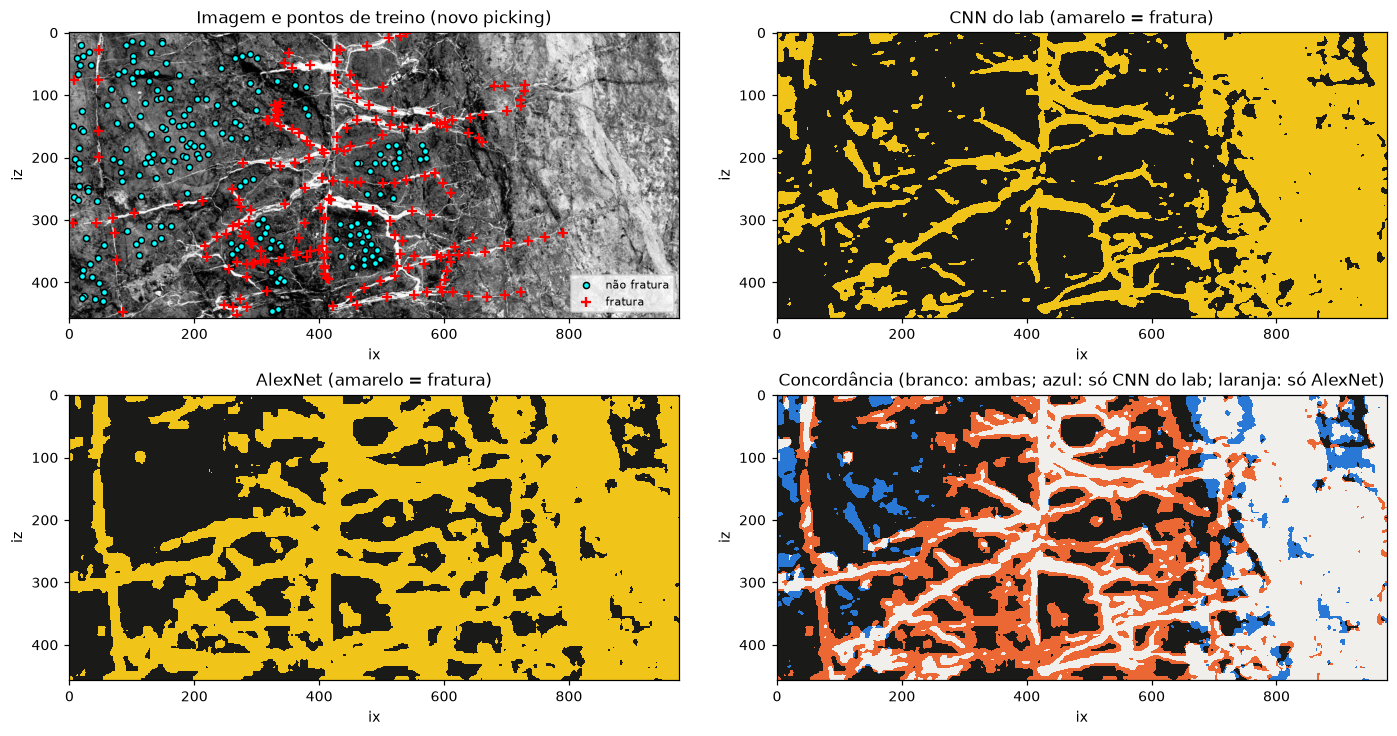

,CNN do lab,AlexNet
acerto treino (%),84.4,99.7
acerto validação (%),81.2,97.5
pixels fratura (%),42.4,59.4
fratura em ix ≥ 800 (%),92.9,86.9
regiões de fratura,161,61
fratura em regiões < 50 px (%),1.0,0.1
tempo de treino (s),0.4,102.2
tempo do mapa (s),11.7,137.2
parâmetros,2 570,61 102 842


concordância CNN do lab × AlexNet: 70.9 % dos pixels


In [9]:
cnn_novo = treinar_cnn_lab(novo); c_cnn_novo = mapa_cnn_lab(cnn_novo)
alex_novo = treinar_alexnet(novo); c_alex_novo = mapa_alexnet(alex_novo)
compara(c_cnn_novo, c_alex_novo, novo, 'novo picking')
RES['5. novo: CNN do lab'], RES['5. novo: AlexNet'] = resumo(cnn_novo, c_cnn_novo), resumo(alex_novo, c_alex_novo)
tabela({'CNN do lab': RES['5. novo: CNN do lab'], 'AlexNet': RES['5. novo: AlexNet']})
print(f'concordância CNN do lab × AlexNet: {100 * np.mean(c_cnn_novo == c_alex_novo):.1f} % dos pixels')

## 6. Questões do lab

O lab termina com quatro questões, e todas são respondidas com a AlexNet e com a CNN do lab. As questões 2 e 3 usam o conjunto de treino da seção 5. As questões 1 e 4 precisam de uma nova marcação, separando fraturas grandes e pequenas, e por isso ficam no fim.

### 6.1 Questão 2: mudar a estrutura da CNN

> *Modify the structure of CNN. See how the CNN parameter will change the result.*

A questão trata da estrutura da CNN do lab, então as variantes são dela. Cada uma parte da CNN original e muda uma única coisa, para que o efeito de cada mudança fique isolado:

* **mais filtros:** 12 e 24 filtros nas duas convoluções, em vez de 6 e 12. A rede pode aprender mais padrões e fica com cerca de 4 vezes mais parâmetros;
* **janela de 33 px:** a rede vê uma vizinhança maior de cada pixel ($33\times33$ px em vez de $17\times17$), com mais contexto em volta da fratura. A janela é reduzida, e não ampliada, para $32\times32$;
* **ReLU + max-pooling + entropia cruzada:** a ativação, o tipo de redução e o custo usados nas redes atuais, inclusive na AlexNet. Com essa troca, o passo cai para 0,1: a entropia cruzada e a ReLU produzem gradientes bem maiores que o erro quadrático com sigmoide, e com passo 1 o treino pode travar, com a rede respondendo sempre a mesma classe.

A AlexNet da seção 5.1 entra na comparação como a mudança mais radical: 9 camadas, 61 milhões de parâmetros e pesos pré-treinados. Todas as variantes usam os mesmos pontos e 10 épocas.

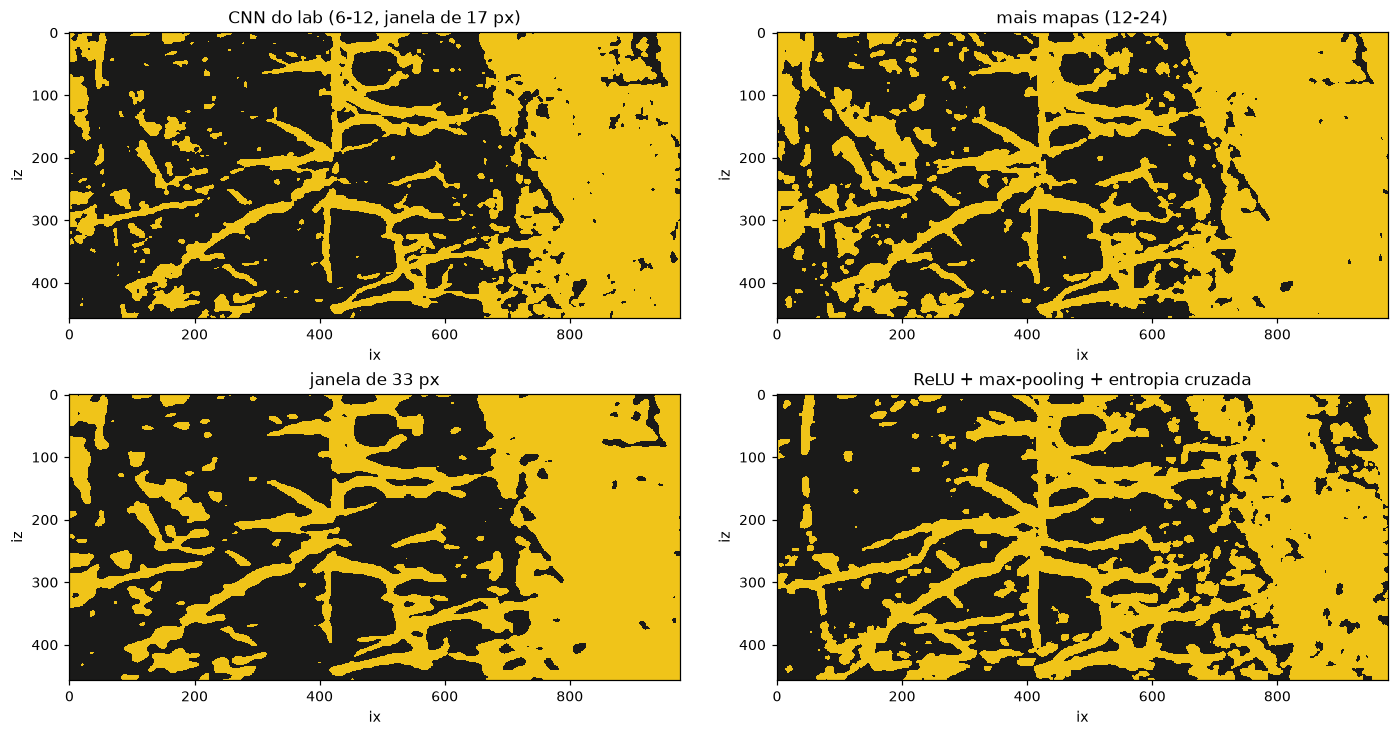

,"CNN do lab (6-12, janela de 17 px)",mais mapas (12-24),janela de 33 px,ReLU + max-pooling + entropia cruzada,AlexNet
acerto treino (%),84.4,79.7,80.0,97.2,99.7
acerto validação (%),81.2,77.5,73.8,97.5,97.5
pixels fratura (%),42.4,53.3,46.4,46.8,59.4
fratura em ix ≥ 800 (%),92.9,97.6,96.2,84.9,86.9
regiões de fratura,161,130,73,122,61
fratura em regiões < 50 px (%),1.0,0.5,0.2,0.3,0.1
tempo de treino (s),0.4,0.5,0.3,0.3,102.2
tempo do mapa (s),11.7,21.0,11.1,11.1,137.2
parâmetros,2 570,8 738,2 570,2 570,61 102 842


In [10]:
VARIANTES = {'mais mapas (12-24)': dict(mapas=(12, 24)),
             'janela de 33 px': dict(wd=16),
             'ReLU + max-pooling + entropia cruzada': dict(moderna=True, alfa=0.1)}
c_var = {'CNN do lab (6-12, janela de 17 px)': c_cnn_novo}
q2 = {'CNN do lab (6-12, janela de 17 px)': RES['5. novo: CNN do lab']}
for nome, arq in VARIANTES.items():
    net = treinar_cnn_lab(novo, **arq)
    c_var[nome] = mapa_cnn_lab(net)
    q2[nome] = RES[f'6.1 Q2: {nome}'] = resumo(net, c_var[nome])
q2['AlexNet'] = RES['5. novo: AlexNet']

fig, ax = plt.subplots(2, 2, figsize=(13, 6.6))
for a, (nome, c) in zip(ax.flat, c_var.items()):
    desenha(a, c, nome)
plt.tight_layout(h_pad=2); plt.show()
tabela(q2)

### 6.2 Questão 3: 100 épocas

> *Increase the iteration number to 100. How the result will change? Why? Is there any way to prevent this problem.*

As duas redes são treinadas por 100 épocas: a CNN do lab, em vez das 10 do lab, com os pontos do lab e com o novo conjunto; a AlexNet, em vez das 6 do exemplo do MATLAB, com o novo conjunto. Com os pontos do lab, a AlexNet já acerta 100 % do treino e da validação em 6 épocas, e a validação, enviesada como o treino, não teria como acusar sobreajuste. Por isso, e porque o treino de 100 épocas da AlexNet leva cerca de 25 min, ela é treinada por mais tempo só com o novo conjunto.

Os gráficos mostram o custo e o acerto a cada época, no treino e na validação. Cada rede tem sua própria linha de gráficos, porque os custos são diferentes: erro quadrático na CNN do lab e entropia cruzada na AlexNet. A linha tracejada marca o número de épocas usado até aqui (10 na CNN do lab e 6 na AlexNet).

**O que observar.** No treino, o custo tende a continuar caindo, porque a rede ajusta os pesos cada vez mais aos 320 pontos que vê. Se, ao mesmo tempo, o custo de validação para de cair ou volta a subir, a rede deixou de aprender o que é uma fratura e passou a decorar os pontos de treino. Esse é o *sobreajuste*. No mapa, ele pode aparecer como fraturas mais fragmentadas e manchas isoladas; o gráfico da direita acompanha essa fragmentação ao longo das épocas na CNN do lab.

**Como evitar.** A forma mais direta é a *parada antecipada*: acompanhar o custo de validação durante o treino e ficar com a rede da época em que ele foi mínimo. Como os sorteios são fixados pela semente, treinar de novo até essa época reproduz a rede daquele momento. A segunda célula faz isso para as três redes treinadas por 100 épocas; se o custo de validação ainda estiver caindo na última época, a parada antecipada fica com a própria rede de 100 épocas. Outras saídas, não testadas aqui, são marcar mais pontos de treino, usar uma rede menor ou penalizar pesos grandes (regularização).

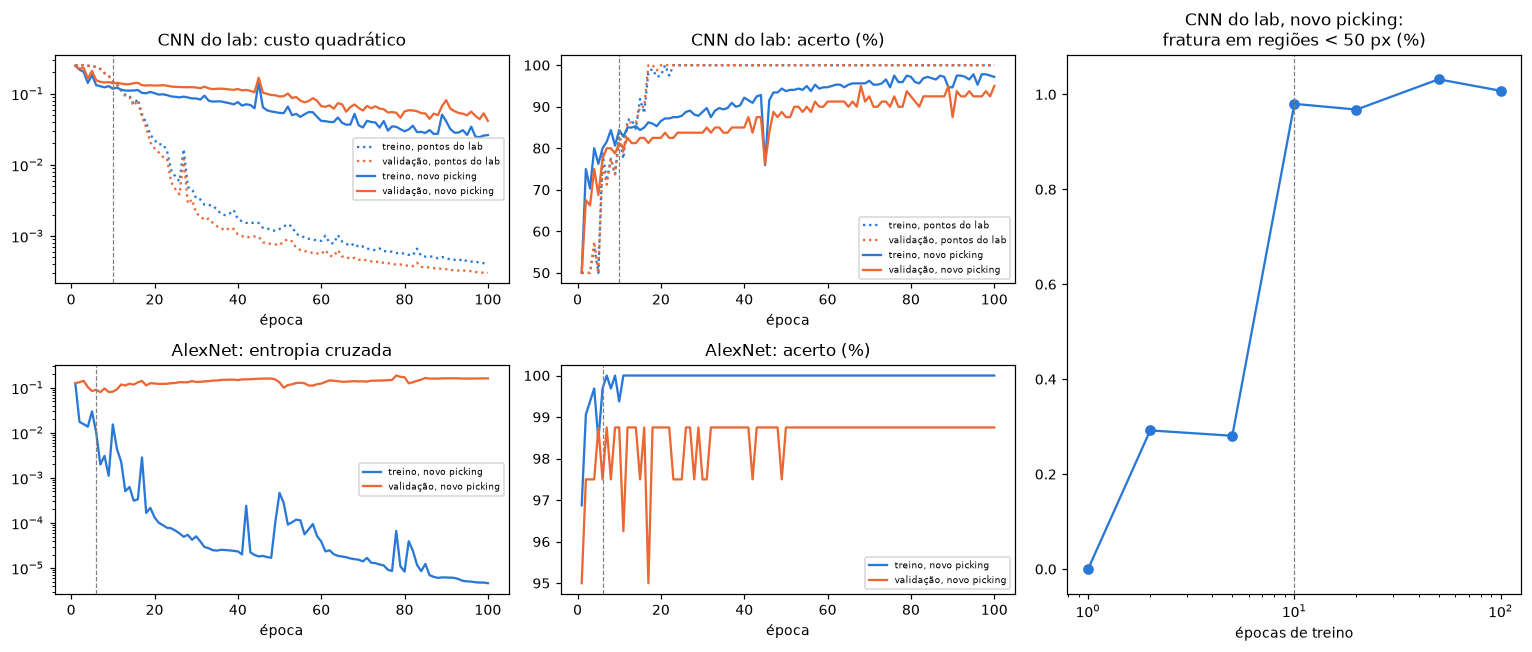

In [11]:
cnn_lab_100 = treinar_cnn_lab(conj_lab, epocas=100); c_cnn_lab_100 = mapa_cnn_lab(cnn_lab_100)
cnn_100 = treinar_cnn_lab(novo, epocas=100); c_cnn_100 = mapa_cnn_lab(cnn_100)
alex_100 = treinar_alexnet(novo, epocas=100); c_alex_100 = mapa_alexnet(alex_100)
EP = [1, 2, 5, 10, 20, 50, 100]                 # com a mesma semente, treinar por e épocas refaz as e primeiras épocas do treino de 100
c_ep = {e: mapa_cnn_lab(treinar_cnn_lab(novo, epocas=e)) for e in EP if e not in (10, 100)} | {10: c_cnn_novo, 100: c_cnn_100}


def curvas(ax_custo, ax_acerto, net, nome, ls):
    h = net.hist
    ax_custo.semilogy(h['custo treino'], ls, color=COR['CNN do lab'], label=f'treino, {nome}')
    ax_custo.semilogy(h['custo validação'], ls, color=COR['AlexNet'], label=f'validação, {nome}')
    ax_acerto.plot(100 * h['acerto treino'], ls, color=COR['CNN do lab'], label=f'treino, {nome}')
    ax_acerto.plot(100 * h['acerto validação'], ls, color=COR['AlexNet'], label=f'validação, {nome}')


fig, ax = plt.subplot_mosaic([['cc', 'ca', 'fr'], ['ac', 'aa', 'fr']], figsize=(14, 6))
curvas(ax['cc'], ax['ca'], cnn_lab_100, 'pontos do lab', ':')
curvas(ax['cc'], ax['ca'], cnn_100, 'novo picking', '-')
curvas(ax['ac'], ax['aa'], alex_100, 'novo picking', '-')
for k, titulo, e in [('cc', 'CNN do lab: custo quadrático', 10), ('ca', 'CNN do lab: acerto (%)', 10),
                     ('ac', 'AlexNet: entropia cruzada', 6), ('aa', 'AlexNet: acerto (%)', 6)]:
    ax[k].axvline(e, color='gray', ls='--', lw=0.8); ax[k].set_xlabel('época'); ax[k].set_title(titulo); ax[k].legend(fontsize=6)
ax['fr'].semilogx(EP, [fragmentos(c_ep[e])[1] for e in EP], 'o-', color=COR['CNN do lab']); ax['fr'].axvline(10, color='gray', ls='--', lw=0.8)
ax['fr'].set_xlabel('épocas de treino'); ax['fr'].set_title('CNN do lab, novo picking:\nfratura em regiões < 50 px (%)')
plt.tight_layout(); plt.show()

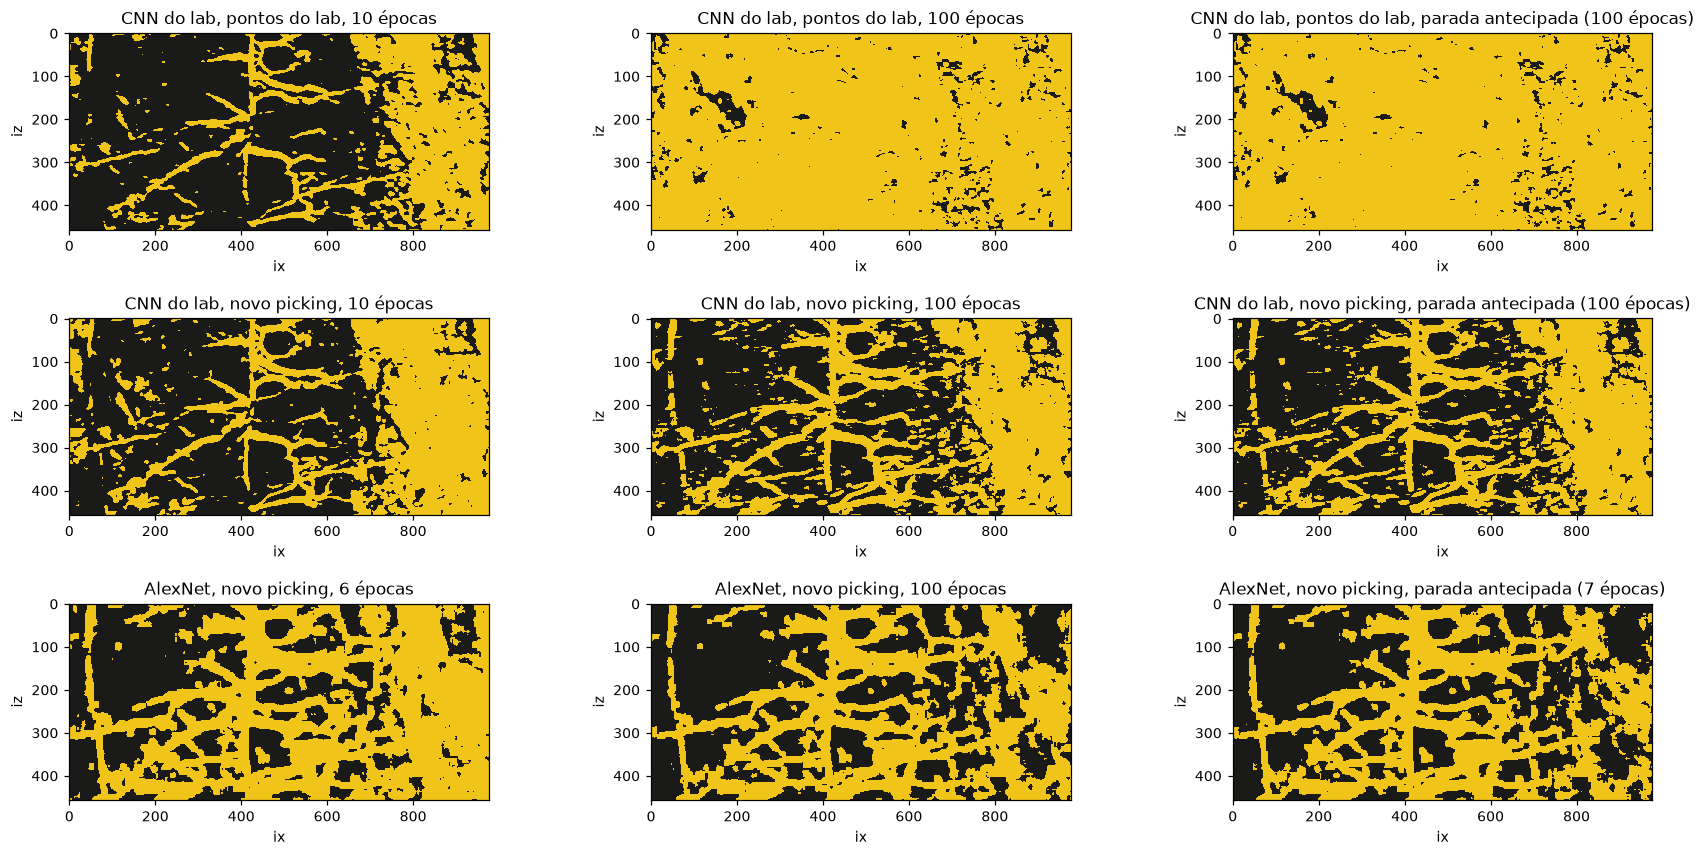

,acerto treino (%),acerto validação (%),pixels fratura (%),fratura em ix ≥ 800 (%),regiões de fratura,fratura em regiões < 50 px (%),tempo de treino (s),tempo do mapa (s),parâmetros
"CNN do lab, pontos do lab, 10 épocas",82.5,83.7,33.3,83.2,151,0.9,0.4,11.2,2 570
"CNN do lab, pontos do lab, 100 épocas",100.0,100.0,94.5,94.8,11,0.0,3.1,9.8,2 570
"CNN do lab, pontos do lab, parada antecipada (100 épocas)",100.0,100.0,94.5,94.8,11,0.0,3.1,9.8,2 570
"CNN do lab, novo picking, 10 épocas",84.4,81.2,42.4,92.9,161,1.0,0.4,11.7,2 570
"CNN do lab, novo picking, 100 épocas",97.2,95.0,46.4,87.8,232,1.0,3.1,9.9,2 570
"CNN do lab, novo picking, parada antecipada (100 épocas)",97.2,95.0,46.4,87.8,232,1.0,3.1,9.9,2 570
"AlexNet, novo picking, 6 épocas",99.7,97.5,59.4,86.9,61,0.1,102.2,137.2,61 102 842
"AlexNet, novo picking, 100 épocas",100.0,98.8,47.5,60.9,67,0.2,1425.4,132.2,61 102 842
"AlexNet, novo picking, parada antecipada (7 épocas)",100.0,98.8,46.8,50.4,86,0.3,99.9,130.7,61 102 842


In [12]:
def parada_antecipada(treinar, mapa, conj, net, c):
    # com a mesma semente, treinar até a época de menor custo de validação refaz o início do treino de 100 épocas
    melhor = int(net.hist['custo validação'].idxmin())
    if melhor == len(net.hist):
        return net, c                       # o custo de validação ainda caía na última época
    net = treinar(conj, epocas=melhor)
    return net, mapa(net)


cnn_lab_cedo, c_cnn_lab_cedo = parada_antecipada(treinar_cnn_lab, mapa_cnn_lab, conj_lab, cnn_lab_100, c_cnn_lab_100)
cnn_cedo, c_cnn_cedo = parada_antecipada(treinar_cnn_lab, mapa_cnn_lab, novo, cnn_100, c_cnn_100)
alex_cedo, c_alex_cedo = parada_antecipada(treinar_alexnet, mapa_alexnet, novo, alex_100, c_alex_100)

q3 = {'CNN do lab, pontos do lab, 10 épocas': (c_cnn_lab, RES['4. lab: CNN do lab']),
      'CNN do lab, pontos do lab, 100 épocas': (c_cnn_lab_100, resumo(cnn_lab_100, c_cnn_lab_100)),
      f'CNN do lab, pontos do lab, parada antecipada ({len(cnn_lab_cedo.hist)} épocas)': (c_cnn_lab_cedo, resumo(cnn_lab_cedo, c_cnn_lab_cedo)),
      'CNN do lab, novo picking, 10 épocas': (c_cnn_novo, RES['5. novo: CNN do lab']),
      'CNN do lab, novo picking, 100 épocas': (c_cnn_100, resumo(cnn_100, c_cnn_100)),
      f'CNN do lab, novo picking, parada antecipada ({len(cnn_cedo.hist)} épocas)': (c_cnn_cedo, resumo(cnn_cedo, c_cnn_cedo)),
      'AlexNet, novo picking, 6 épocas': (c_alex_novo, RES['5. novo: AlexNet']),
      'AlexNet, novo picking, 100 épocas': (c_alex_100, resumo(alex_100, c_alex_100)),
      f'AlexNet, novo picking, parada antecipada ({len(alex_cedo.hist)} épocas)': (c_alex_cedo, resumo(alex_cedo, c_alex_cedo))}

fig, ax = plt.subplots(3, 3, figsize=(16, 7.8))
for a, (nome, (c, _)) in zip(ax.flat, q3.items()):
    desenha(a, c, nome)
plt.tight_layout(h_pad=2); plt.show()

RES.update({f'6.2 Q3: {k}': r for k, (_, r) in q3.items() if not k.endswith((' 10 épocas', ' 6 épocas'))})
tabela({k: r for k, (_, r) in q3.items()}, transpor=True)

### 6.3 Questão 1: só fraturas grandes ou só fraturas pequenas

> *Pick the training set manually by yourself. You can focus on big crack only or small crack only. See how the result will be looks like.*

Uma segunda figura interativa, com os mesmos comandos da seção 5, marcou primeiro 100 **fraturas grandes** (largas e contínuas, círculos laranja) e depois 100 **fraturas pequenas** (finas, curtas ou pouco contrastadas, círculos magenta). Os pontos estão salvos em `picks_grandes_pequenas.csv`; para marcar de novo, ponha `REFAZER_GRANDES_PEQUENAS = True`.

Depois, cada rede é treinada duas vezes: uma com **só fraturas grandes** e outra com **só fraturas pequenas**, sempre contra pontos "não fratura". Para que a única diferença entre os dois treinos sejam as fraturas, os dois usam os mesmos 100 pontos "não fratura", sorteados entre os da seção 5. Assim, as duas classes ficam com o mesmo número de pontos, como no lab.

In [20]:
REFAZER_GRANDES_PEQUENAS = False
N_GRANDE, N_PEQUENA = 100, 100
ARQ_GP = Path('picks_grandes_pequenas.csv')
ESTILO_GP = {0: ESTILO[0],
             1: dict(marker='o', mfc='orange', mec='k', ms=5, label='fratura grande'),
             2: dict(marker='o', mfc='magenta', mec='k', ms=4, label='fratura pequena')}

pick_gp = picking([(1, N_GRANDE, 'FRATURAS GRANDES', ESTILO_GP[1], 'darkorange'),
                   (2, N_PEQUENA, 'FRATURAS PEQUENAS', ESTILO_GP[2], 'darkmagenta')], ARQ_GP, REFAZER_GRANDES_PEQUENAS,
                  referencia=lab[lab.classe == 1])

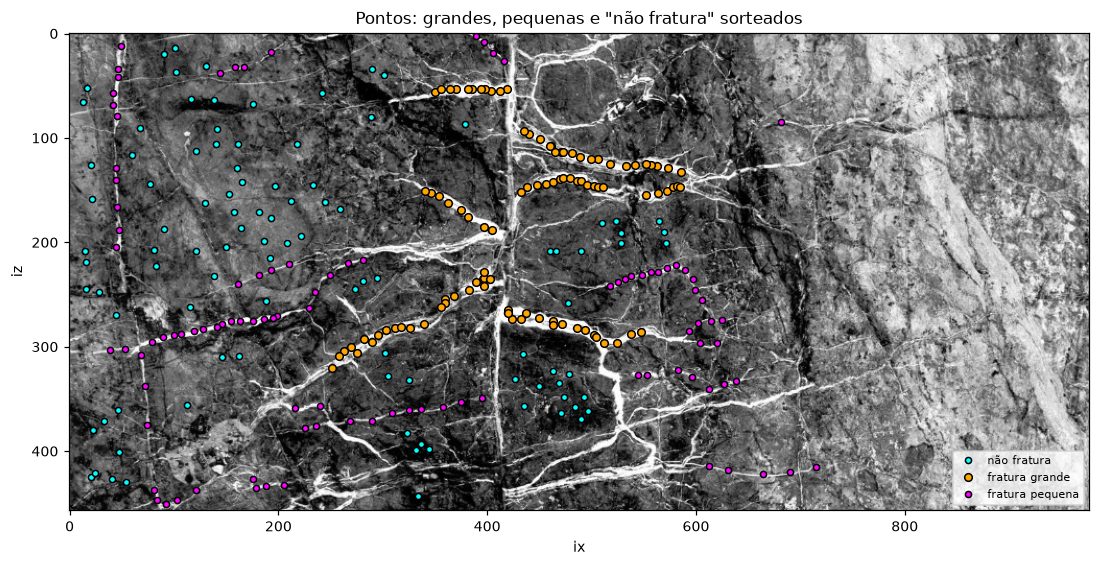

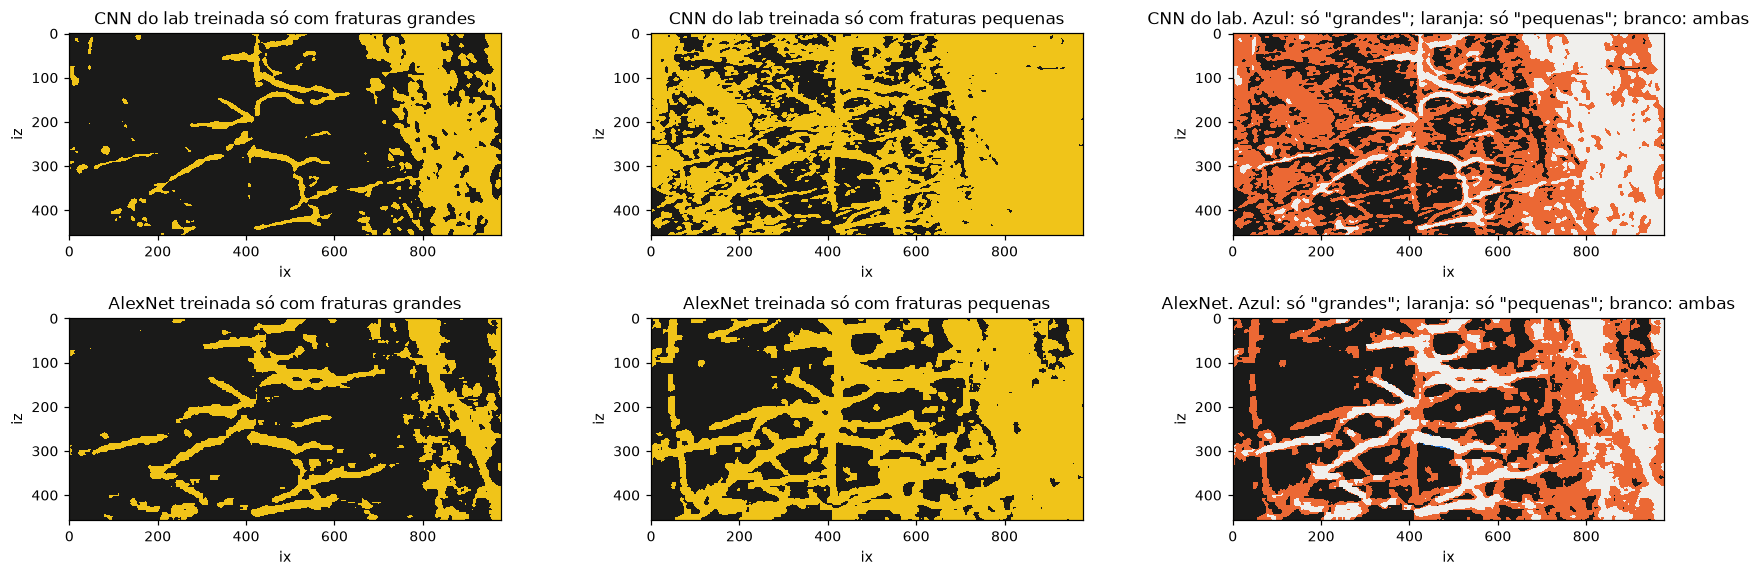

,acerto treino (%),acerto validação (%),pixels fratura (%),fratura em ix ≥ 800 (%),regiões de fratura,fratura em regiões < 50 px (%),tempo de treino (s),tempo do mapa (s),parâmetros
"CNN do lab, só grandes",99.4,100.0,24.5,73.8,100,0.6,0.2,10.0,2 570
"CNN do lab, só pequenas",73.8,72.5,70.5,99.5,100,0.4,0.2,9.7,2 570
"AlexNet, só grandes",100.0,100.0,21.3,45.0,106,0.7,42.0,131.9,61 102 842
"AlexNet, só pequenas",100.0,95.0,55.9,91.5,56,0.1,42.3,133.2,61 102 842
"CNN do lab, fraturas do lab (seção 5.1)",84.4,81.2,42.4,92.9,161,1.0,0.4,11.7,2 570
"AlexNet, fraturas do lab (seção 5.1)",99.7,97.5,59.4,86.9,61,0.1,102.2,137.2,61 102 842


In [14]:
gp = carregar(ARQ_GP)
fundo = nao.sample(N_GRANDE, random_state=SEMENTE)              # mesmo sorteio de "não fratura" para os dois treinos
so_grandes = dividir(pd.concat([fundo, gp[gp.classe == 1]], ignore_index=True))
so_pequenas = dividir(pd.concat([fundo, gp[gp.classe == 2].assign(classe=1)], ignore_index=True))
cnn_g = treinar_cnn_lab(so_grandes); c_g = mapa_cnn_lab(cnn_g)
cnn_p = treinar_cnn_lab(so_pequenas); c_p = mapa_cnn_lab(cnn_p)
alex_g = treinar_alexnet(so_grandes); c_alex_g = mapa_alexnet(alex_g)
alex_p = treinar_alexnet(so_pequenas); c_alex_p = mapa_alexnet(alex_p)

fig, ax = plt.subplots(figsize=(11, 5.2))
mostra(ax, pd.concat([fundo, gp]), 'Pontos: grandes, pequenas e "não fratura" sorteados', ESTILO_GP)
ax.legend(loc='lower right', fontsize=7)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 3, figsize=(16, 5.2))
for a, (rede, g, p) in zip(ax, [('CNN do lab', c_g, c_p), ('AlexNet', c_alex_g, c_alex_p)]):
    desenha(a[0], g, f'{rede} treinada só com fraturas grandes')
    desenha(a[1], p, f'{rede} treinada só com fraturas pequenas')
    desenha(a[2], g + 2 * p, f'{rede}. Azul: só "grandes"; laranja: só "pequenas"; branco: ambas', CONCORDA)
plt.tight_layout(h_pad=2); plt.show()

q1 = {'CNN do lab, só grandes': resumo(cnn_g, c_g), 'CNN do lab, só pequenas': resumo(cnn_p, c_p),
      'AlexNet, só grandes': resumo(alex_g, c_alex_g), 'AlexNet, só pequenas': resumo(alex_p, c_alex_p)}
RES.update({f'6.3 Q1: {k}': v for k, v in q1.items()})
tabela(q1 | {'CNN do lab, fraturas do lab (seção 5.1)': RES['5. novo: CNN do lab'],
             'AlexNet, fraturas do lab (seção 5.1)': RES['5. novo: AlexNet']}, transpor=True)

### 6.4 Questão 4: classificação com três classes

> *Try to do multi-class classification using this code. Such as background, crack class 1 and crack class 2.*

Nenhuma das duas redes precisa de mudança na arquitetura para separar mais de duas classes: basta que a última camada tenha uma saída por classe. Na CNN do lab, é a camada totalmente conectada; na AlexNet, é a fc9, que passa a ter 3 saídas (1 000 → 3). As redes são treinadas com os pontos da seção 6.3: os 100 pontos "não fratura" como **fundo** e as **fraturas grandes** e **fraturas pequenas** como as outras duas classes. Cada pixel recebe a classe de maior nota.

As matrizes de confusão, calculadas nos pontos de validação, mostram quais classes cada rede confunde entre si.

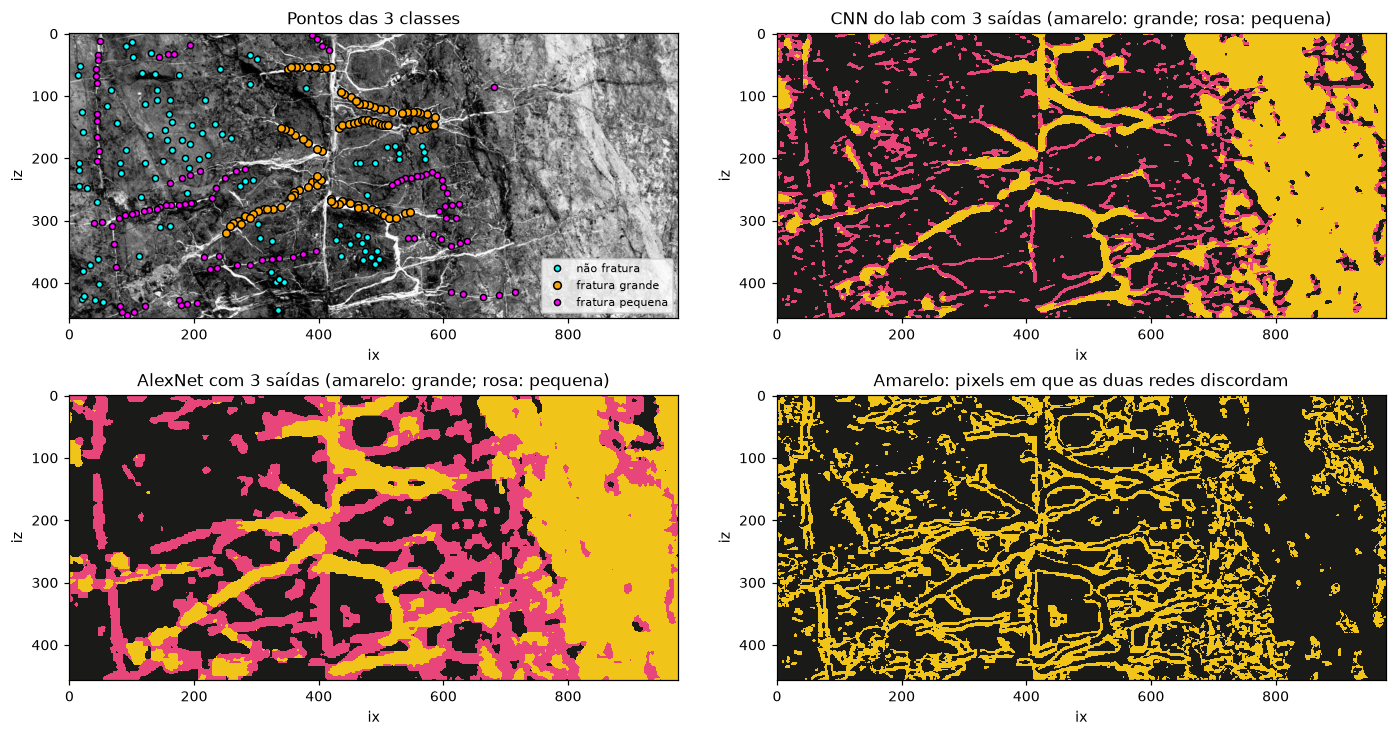

CNN do lab                                AlexNet  \
prevista             fundo fratura grande fratura pequena   fundo   
verdadeira                                                          
fratura grande           0             20               0       0   
fratura pequena          4              3              13       0   
fundo                   18              0               2      20   

                                                
prevista        fratura grande fratura pequena  
verdadeira                                      
fratura grande              20               0  
fratura pequena              1              19  
fundo                        0               0

CNN do lab: pixels por classe: fundo 57.7 %, fratura grande 28.6 %, fratura pequena 13.8 %; acerto: treino 87.5 %, validação 85.0 %
AlexNet: pixels por classe: fundo 41.2 %, fratura grande 31.8 %, fratura pequena 27.0 %; acerto: treino 98.8 %, validação 98.3 %


In [15]:
NOMES = ['fundo', 'fratura grande', 'fratura pequena']
TRES = ListedColormap(['#1a1a19', '#f0c419', '#e8457a'])
multi = dividir(pd.concat([fundo, gp], ignore_index=True))
cnn_m = treinar_cnn_lab(multi); c_m = mapa_cnn_lab(cnn_m)
alex_m = treinar_alexnet(multi); c_alex_m = mapa_alexnet(alex_m)

fig, ax = plt.subplots(2, 2, figsize=(13, 6.6))
mostra(ax[0, 0], multi, 'Pontos das 3 classes', ESTILO_GP); ax[0, 0].legend(loc='lower right', fontsize=7)
desenha(ax[0, 1], c_m, 'CNN do lab com 3 saídas (amarelo: grande; rosa: pequena)', TRES)
desenha(ax[1, 0], c_alex_m, 'AlexNet com 3 saídas (amarelo: grande; rosa: pequena)', TRES)
desenha(ax[1, 1], c_m != c_alex_m, 'Amarelo: pixels em que as duas redes discordam')
plt.tight_layout(h_pad=2); plt.show()

v = multi[multi.val]
x = janelas(v.iz.values, v.ix.values)
verdadeira = pd.Series(v.classe.map(dict(enumerate(NOMES))).values, name='verdadeira')
conf = {}
with torch.inference_mode():
    for rede, prev in [('CNN do lab', cnn_m(x)), ('AlexNet', alex_m(entrada_alexnet(x)))]:
        prevista = pd.Categorical(prev.argmax(1).numpy(), categories=range(3)).rename_categories(NOMES)
        conf[rede] = pd.crosstab(verdadeira, pd.Series(prevista, name='prevista'), dropna=False)
display(pd.concat(conf, axis=1))
RES['6.4 Q4: CNN do lab, 3 classes'], RES['6.4 Q4: AlexNet, 3 classes'] = resumo(cnn_m, c_m), resumo(alex_m, c_alex_m)
for rede, net, c in [('CNN do lab', cnn_m, c_m), ('AlexNet', alex_m, c_alex_m)]:
    print(f'{rede}: pixels por classe: ' + ', '.join(f'{n} {100 * np.mean(c == k):.1f} %' for k, n in enumerate(NOMES))
          + f"; acerto: treino {100 * net.hist['acerto treino'].iloc[-1]:.1f} %, validação {100 * net.hist['acerto validação'].iloc[-1]:.1f} %")

## 7. Resumo dos experimentos

A tabela reúne as medidas de todos os experimentos do notebook.

In [16]:
tabela(RES, transpor=True)

,acerto treino (%),acerto validação (%),pixels fratura (%),fratura em ix ≥ 800 (%),regiões de fratura,fratura em regiões < 50 px (%),tempo de treino (s),tempo do mapa (s),parâmetros
4. lab: CNN do lab,82.5,83.7,33.3,83.2,151,0.9,0.4,11.2,2 570
4. lab: AlexNet,100.0,100.0,85.5,77.1,38,0.1,105.0,190.2,61 102 842
5. novo: CNN do lab,84.4,81.2,42.4,92.9,161,1.0,0.4,11.7,2 570
5. novo: AlexNet,99.7,97.5,59.4,86.9,61,0.1,102.2,137.2,61 102 842
6.1 Q2: mais mapas (12-24),79.7,77.5,53.3,97.6,130,0.5,0.5,21.0,8 738
6.1 Q2: janela de 33 px,80.0,73.8,46.4,96.2,73,0.2,0.3,11.1,2 570
6.1 Q2: ReLU + max-pooling + entropia cruzada,97.2,97.5,46.8,84.9,122,0.3,0.3,11.1,2 570
"6.2 Q3: CNN do lab, pontos do lab, 100 épocas",100.0,100.0,94.5,94.8,11,0.0,3.1,9.8,2 570
"6.2 Q3: CNN do lab, pontos do lab, parada antecipada (100 épocas)",100.0,100.0,94.5,94.8,11,0.0,3.1,9.8,2 570
"6.2 Q3: CNN do lab, novo picking, 100 épocas",97.2,95.0,46.4,87.8,232,1.0,3.1,9.9,2 570


## Discussão

### Os dados de treino pesam mais que a rede

Com os pontos do lab, a AlexNet marca 85 % da imagem como fratura e, mesmo assim, acerta 100 % dos pontos de validação. Os 200 pontos "não fratura" do lab estão num canto de $9\times17$ px, então a rede aprende que "não fratura" é a textura daquele canto e que todo o resto é fratura. Os pontos de validação têm o mesmo viés e não percebem o erro.

Com os 200 novos pontos "não fratura", espalhados pela rocha escura das partes esquerda e central, a mesma AlexNet passa a marcar 59 % da imagem como fratura, e a rocha escura entre as fraturas deixa de ser confundida com fratura. A arquitetura, os hiperparâmetros e os pontos de fratura são os mesmos; só mudaram os exemplos de "não fratura".

O limite dessa correção aparece na faixa clara da direita (ix ≥ 800). Ela não recebeu nenhum ponto "não fratura", e 87 % dela continua classificada como fratura pela AlexNet (93 % pela CNN do lab). A rocha dessa faixa é tão clara quanto as fraturas, e nada no treino ensina às redes que rocha clara pode não ser fratura. Uma rede não generaliza para um tipo de rocha que nunca viu: para corrigir essa faixa, é preciso marcar pontos "não fratura" nela.

### AlexNet × CNN do lab: os números e os mapas

Pelos números, a AlexNet vence todas as comparações. Com o novo conjunto de treino, ela acerta 97,5 % dos pontos de validação, contra 81,2 % da CNN do lab, e a vantagem cresce nas tarefas mais difíceis: separar fraturas pequenas da rocha (95,0 % contra 72,5 %, questão 1) e separar três classes (98,3 % contra 85,0 %, questão 4). O mapa dela também tem menos regiões de fratura (61 contra 161) e quase nenhuma mancha isolada.

Os mapas, porém, contam outra história. Com 10 épocas, a CNN do lab desenha fraturas finas, que acompanham os veios claros da foto, separam veios próximos e preservam as ramificações, tanto com os pontos do lab quanto com o novo conjunto. As fraturas da AlexNet são grosseiras: várias vezes mais largas que os veios, com bordas serrilhadas, e veios vizinhos se fundem numa faixa única, como em volta da fratura vertical em ix ≈ 420. O painel de concordância da seção 5.1 mostra isso: a maior parte do laranja, que só a AlexNet marca, forma uma borda em volta das fraturas que as duas redes marcam. Visualmente, é a CNN do lab, com 2 570 parâmetros, que produz o mapa mais fiel à foto.

A contradição vem do que as medidas conseguem ver. Os pontos de validação, como os de treino, estão no meio dos veios ou no meio da rocha escura, e nenhum está na borda de uma fratura, justamente onde as redes divergem. Uma rede que marca uma faixa larga em volta de cada veio acerta todos eles. E as poucas regiões e a ausência de manchas pequenas, que pareciam sinal de fraturas contínuas, vêm, na AlexNet, das próprias fraturas largas, que se juntam numa única rede conectada. Nenhuma das medidas avalia a largura das fraturas, que é o principal defeito da AlexNet.

Além disso, a AlexNet custa muito mais: 61 milhões de parâmetros contra 2 570, cerca de 100 s de treino contra menos de 1 s, e cerca de 2 min para o mapa, mesmo classificando só um pixel a cada 4, contra 10 s para todos os pixels na CNN do lab.

### Por que a AlexNet produz mapas grosseiros

Uma explicação provável é o tamanho da rede diante da quantidade de dados. Cada pixel é classificado pela janela de $17\times17$ px em volta dele, e um pixel a poucos pixels de um veio claro já tem o veio dentro da janela. Para decidir se esse pixel é fratura, a rede precisa saber onde a fratura termina, e nada no treino ensina isso: nenhum ponto "não fratura" está perto de uma fratura, então qualquer fronteira entre "sobre o veio" e "longe do veio" separa os pontos marcados.

A CNN do lab, com 2 570 parâmetros e 10 épocas de treino, fica com uma regra simples, próxima de "pixel claro no centro da janela = fratura", e essa regra segue o contorno dos veios. A AlexNet tem 61 milhões de parâmetros para 320 pontos de treino e chega a um custo de treino de $10^{-5}$: ela separa os pontos com folga e tem liberdade para pôr a fronteira em qualquer lugar. Com filtros treinados para reconhecer objetos em fotos, ela tende a responder se há um veio na janela, e não se o centro da janela está sobre ele. A janela de 33 px da questão 2 produz um efeito parecido por outro caminho: quando a decisão depende de mais rocha em volta do pixel, as fraturas engordam. Já a grade de 4 px usada no mapa da AlexNet explica o serrilhado das bordas, mas não a largura, que equivale a várias células da grade.

Duas mudanças podem reduzir esse problema:

* **Mais dados, no lugar certo.** É o caminho mais direto: pontos "não fratura" a poucos pixels da borda das fraturas, que ensinam onde a fratura termina, e mais pontos sobre fraturas finas. Mais pontos também reduzem o sobreajuste de uma rede desse tamanho.
* **Uma parte totalmente conectada maior** anexada à AlexNet, por exemplo com uma camada intermediária entre a fc8 e a saída. Sozinha, porém, essa mudança dificilmente afinaria as fraturas: a AlexNet já decora os pontos de treino, então não lhe falta capacidade, e sim informação sobre a borda das fraturas. Ela faz mais sentido junto com um conjunto de treino maior.

### Questão 2: estrutura da CNN

Mais filtros (12 e 24) e uma janela maior (33 px) não melhoraram a CNN do lab: o acerto de validação caiu para 77,5 % e 73,8 %, a área marcada como fratura aumentou, e as fraturas ficaram mais largas. Com a janela de 33 px, cada janela mistura mais rocha em volta do pixel, e o mapa fica parecido com o da AlexNet: suave, com fraturas largas e veios próximos fundidos.

A mudança que fez diferença foi trocar sigmoide, média e erro quadrático por ReLU, max-pooling e entropia cruzada. Com os mesmos 2 570 parâmetros, o acerto de validação foi de 81,2 % para 97,5 %, o mesmo da AlexNet, e o mapa manteve as fraturas finas da CNN do lab, com menos manchas isoladas. É a variante que reúne o acerto da AlexNet e a precisão espacial da CNN pequena. O acerto da AlexNet, portanto, não exige uma rede grande nem pré-treinada: vem em boa parte do jeito de treinar. Com sigmoide e erro quadrático, os gradientes são pequenos e a rede aprende devagar: nas curvas da questão 3, com os pontos do lab, ela fica perto de 50 % de acerto nas primeiras épocas.

### Questão 3: 100 épocas

Com 100 épocas, a vantagem visual da CNN do lab desaparece: as duas redes sobreajustam, embora isso nem sempre apareça nas curvas.

* **CNN do lab com os pontos do lab:** a rede passa a marcar 94,5 % da imagem como fratura, contra 33 % com 10 épocas, e acerta 100 % do treino e da validação. É o sobreajuste levado ao extremo: a rede aprende com precisão cada vez maior a textura do canto superior esquerdo, e tudo o que não é exatamente aquilo vira fratura. A parada antecipada não ajuda, porque a validação tem o mesmo viés: o custo de validação cai até a época 100, e a "melhor" rede é a última.
* **CNN do lab com o novo conjunto:** pelos números, as 100 épocas melhoram a rede. Os custos de treino e de validação caem juntos até o fim, e o acerto de validação sobe de 81 % para 95 %. O mapa, porém, piora: as fraturas finas de 10 épocas dão lugar a uma trama densa de linhas e manchas, e a rede passa a marcar como fratura a textura da rocha escura, por exemplo na parte inferior esquerda da imagem. O número de regiões de fratura sobe de 161 para 232. A rede continua se ajustando aos pontos marcados, todos no meio de veios ou no meio da rocha, e os pontos de validação, do mesmo tipo, não mostram o que acontece no resto da imagem. As 10 épocas do lab funcionavam como uma regularização: a rede parava antes de aprender detalhes que não generalizam.
* **AlexNet com o novo conjunto:** aqui, o sobreajuste aparece da forma clássica nas curvas. O custo de treino cai até $10^{-5}$, ou seja, a rede decora os 320 pontos de treino, enquanto o custo de validação atinge o mínimo na época 7, sobe e se estabiliza em cerca do dobro desse valor. O acerto de validação, porém, fica entre 97,5 % e 98,8 % o tempo todo. No mapa, as fraturas são grosseiras em todas as versões, e com 100 épocas a região entre ix ≈ 600 e 800 fica mais fragmentada. A faixa clara da direita é a que mais muda: a fração de fratura nela é de 87 % com 6 épocas, 50 % com 7 e 61 % com 100. Uma única época muda a classificação de mais de um terço da faixa sem nenhum efeito no acerto de validação: nessa região, a resposta da rede é uma extrapolação instável.

**Como evitar.** A parada antecipada é barata e, na AlexNet, parou na época 7, mas não resolve o problema. Ela escolhe a época pelo custo nos pontos de validação, que não enxergam o que acontece entre os pontos marcados. Na CNN do lab, ela fica com a rede de 100 épocas nos dois conjuntos, embora o mapa de 10 épocas seja visivelmente melhor; na AlexNet, as fraturas já são grosseiras na época 6. Para que a validação acompanhe a qualidade do mapa, ela precisa de pontos onde o mapa erra: na borda das fraturas, na faixa da direita e em regiões não usadas no treino. Enquanto isso, poucas épocas, como as 10 do lab, redes pequenas e mais pontos de treino são a proteção mais segura.

### Questão 1: só fraturas grandes ou só fraturas pequenas

Treinadas só com fraturas grandes, as duas redes acertam 100 % da validação e produzem os mapas mais limpos do notebook, só com as fraturas principais (24,5 % da imagem na CNN do lab e 21,3 % na AlexNet). Também aqui, a CNN do lab desenha fraturas finas e bem delimitadas, e a AlexNet desenha as mesmas fraturas, só que mais largas. Em compensação, as fraturas finas somem dos dois mapas.

Treinar só com fraturas pequenas é bem mais difícil, porque fraturas finas e pouco contrastadas se parecem com a textura da rocha. Neste caso, os números e os mapas concordam. A CNN do lab não consegue separá-las (72,5 % na validação) e marca 70,5 % da imagem, numa trama de manchas que não segue as fraturas da foto. A AlexNet acerta 95,0 % e desenha uma rede de fraturas coerente, embora com a mesma largura excessiva das outras seções. É o caso em que a AlexNet produz, também visualmente, o melhor mapa.

Nos painéis de concordância quase não há azul: o que a rede treinada com fraturas grandes marca, a treinada com fraturas pequenas também marca. Uma rede que aprendeu a reconhecer fraturas finas reconhece também as grandes, mas o contrário não acontece. Treinar só com fraturas grandes dá um mapa conservador, que perde as fraturas finas; treinar com as pequenas dá um mapa mais completo, mas que também marca mais rocha como fratura, inclusive quase toda a faixa da direita.

### Questão 4: três classes

Nenhuma das redes precisou de mudança na arquitetura além de uma saída a mais. Pelos números, a AlexNet separa as três classes quase sem erro: acerta 98,3 % da validação, com um único erro, uma fratura pequena classificada como grande. A CNN do lab acerta 85,0 % e confunde sobretudo fraturas pequenas com fundo (4 casos) e com fraturas grandes (3 casos).

Nos mapas, a comparação se inverte de novo. A CNN do lab desenha as fraturas grandes finas, com uma borda estreita de "fratura pequena" e veios finos isolados, embora com muitas manchas pequenas (363 regiões). A AlexNet desenha faixas largas de "fratura grande" envoltas em faixas também largas de "fratura pequena", que ocupam boa parte da rocha entre as fraturas.

Nos dois mapas, a classe "fratura pequena" aparece em veios finos isolados, mas também como uma borda em volta das fraturas grandes. Na beira de uma fratura grande, a janela de 17 px pega só parte do veio claro, e essa janela se parece com a de uma fratura fina. O painel de discordância mostra que as redes divergem justamente nessas bordas, o mesmo lugar onde divergem na classificação binária e onde não há nenhum ponto de treino ou de validação. A faixa da direita vira "fratura grande" nas duas redes, pelo mesmo motivo das seções anteriores.

### Conclusões

* **Pelos números**, a AlexNet, o classificador pedido na atividade, é a melhor rede: com o novo conjunto, fica à frente ou empatada em todas as comparações de acerto de validação, com grande vantagem nas tarefas difíceis (fraturas pequenas e três classes).
* **Pelos mapas**, não é. Com 10 épocas, a CNN do lab, tanto com os pontos do lab quanto com os novos pontos, desenha fraturas finas que acompanham os veios da foto e parecem mais precisas. A AlexNet produz fraturas grosseiras, largas e fundidas, apesar do ótimo acerto na validação. As medidas usadas não avaliam a largura das fraturas, e os pontos de validação não estão onde as redes erram.
* A CNN do lab com ReLU, max-pooling e entropia cruzada alcança o acerto da AlexNet (97,5 %) mantendo as fraturas finas, com 2 570 parâmetros.
* **Com 100 épocas**, a vantagem visual da CNN do lab desaparece, porque as duas redes sobreajustam. A CNN do lab passa a marcar a textura da rocha (ou quase a imagem toda, com os pontos do lab), e a AlexNet decora os pontos de treino, com custo de validação crescente depois da época 7. A parada antecipada pela validação não recupera a qualidade do mapa de 10 épocas.
* O aspecto grosseiro da AlexNet parece vir do tamanho da rede diante dos dados: 61 milhões de parâmetros para 320 pontos de treino, sem nenhum exemplo que mostre onde a fratura termina. O caminho mais promissor é marcar mais pontos, principalmente pontos "não fratura" na borda das fraturas e na faixa clara da direita. Uma parte totalmente conectada maior anexada à AlexNet pode ser testada, mas só deve ajudar junto com mais dados.
* A qualidade do mapa depende mais dos pontos de treino do que da rede: só a troca dos pontos "não fratura" leva a AlexNet de 85 % para 59 % da imagem marcada como fratura, e a faixa da direita, sem exemplos, continua errada em todos os experimentos.
* Para avaliar um mapa de fraturas, o acerto em pontos marcados não basta. Seria preciso um gabarito pixel a pixel de parte da imagem, ou pontos de validação nas bordas das fraturas e em regiões não usadas no treino. Com um gabarito desses, também seria possível treinar uma rede de segmentação, como a U-Net, que classifica todos os pixels de uma vez e aprende diretamente a largura das fraturas.